In [16]:
import sys
from pathlib import Path

ROOT_DIR = Path.cwd().parent
DATA_DIR = ROOT_DIR / "data"

DATA_DIR.mkdir(exist_ok=True)

sys.path.insert(0, str(ROOT_DIR))

In [17]:
import yfinance as yf
import numpy as np
import pandas as pd

data = yf.download(
    "^NSEI",
    period="5y",
    interval="1d",
    auto_adjust=False,
    progress=False
)
data.to_csv(DATA_DIR / "nifty50.csv")
close = data["Close"].squeeze().dropna()

prices = close.to_numpy(dtype=float)
dates = close.index

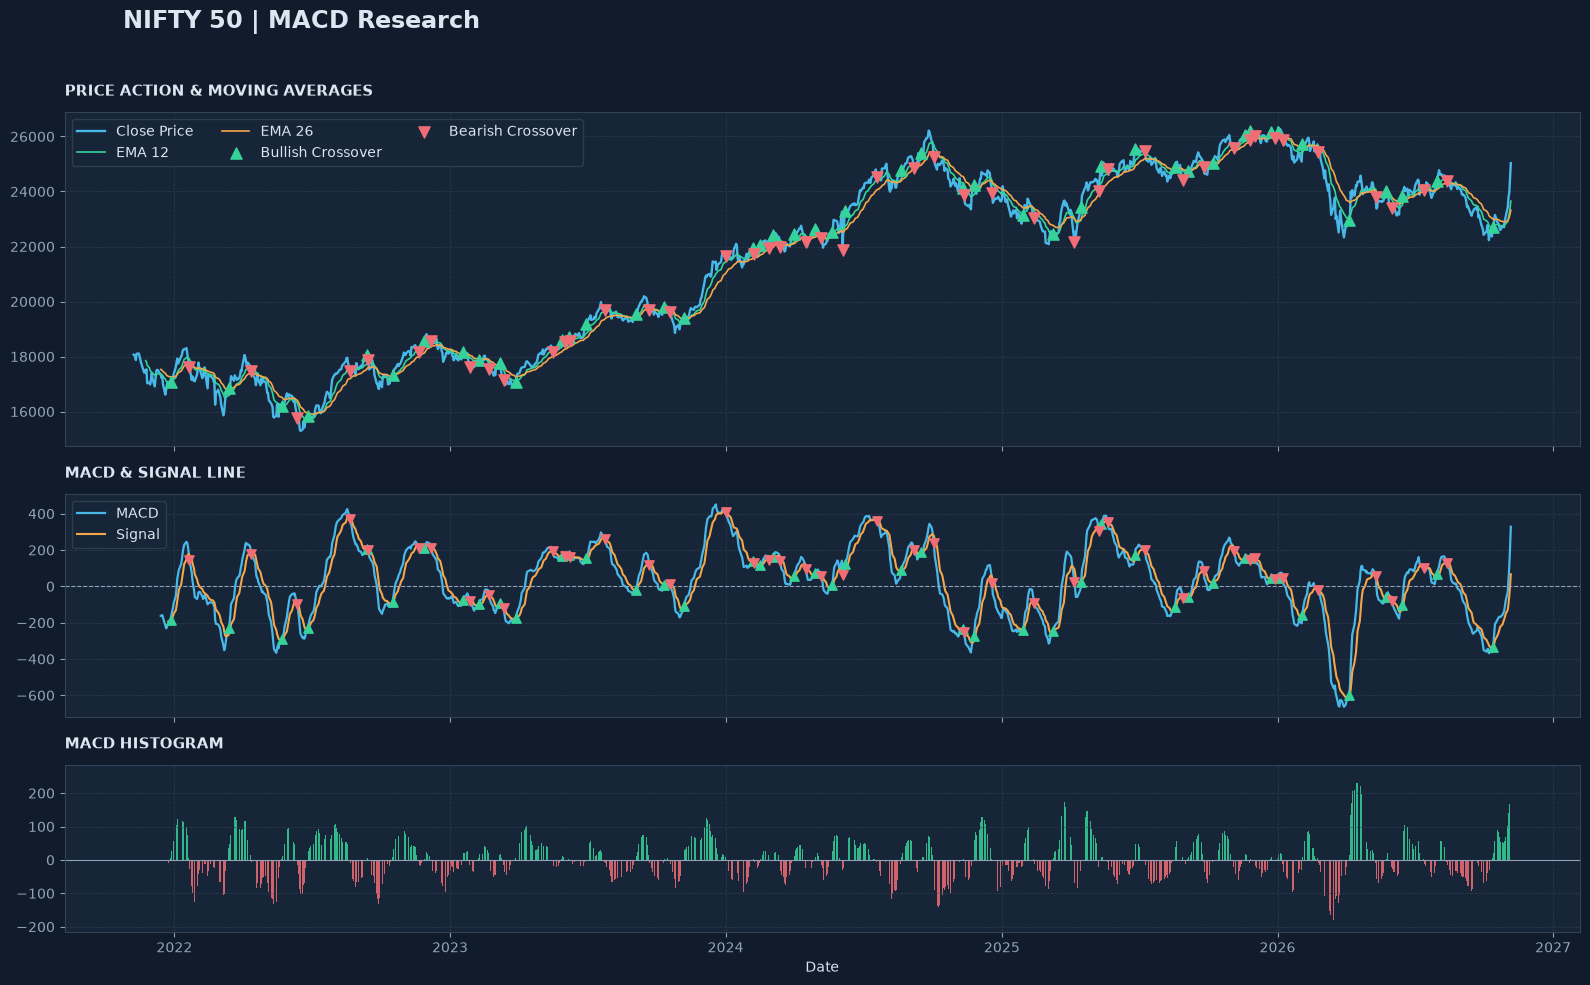

In [18]:
from src.ema import calculate_ema
from src.macd import calculate_macd
from src.signals import detect_crossovers
from src.visualization import plot_macd_dashboard
result = calculate_macd(prices)

macd = result["macd"]
signal = result["signal"]
histogram = result["histogram"]

bullish, bearish = detect_crossovers(
    macd, signal
)

plot_macd_dashboard(
    dates,
    prices,
    calculate_ema(prices, 12),
    calculate_ema(prices, 26),
    macd,
    signal,
    histogram,
    bullish,
    bearish,
    title="NIFTY 50 | MACD Research"
)